# Projet 8 : Lapage - Analysez les ventes d'une librairie - Test statistiques

## Partie 1 : Importation et nettoyage des données

### 1-1 : Importation des librairies et chargement des fichiers


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Importation du fichier customers.csv
customers = pd.read_csv("C:/Users/capel/Desktop/Data Analyst/Projet 8/DAN-P6-donnees/customers.csv")
#Importation du fichier products.csv
products = pd.read_csv("C:/Users/capel/Desktop/Data Analyst/Projet 8/DAN-P6-donnees/products.csv")
#Importation du fichier transactions.csv
transactions = pd.read_csv("C:/Users/capel/Desktop/Data Analyst/Projet 8/DAN-P6-donnees/transactions.csv")


### 1-2 : Jonction des fichiers

In [3]:
transactions_products = pd.merge(transactions, products, on='id_prod', how='left')

In [4]:
lapage = pd.merge(transactions_products, customers, on='client_id', how='left')

In [5]:
mediane_categ0 = lapage.loc[lapage['categ'] == 0, 'price'].median()
lapage.loc[lapage['id_prod'] == '0_2245', ['price', 'categ']] = [mediane_categ0, 0]
print(pd.DataFrame(lapage).count())

id_prod       679532
date          679532
session_id    679532
client_id     679532
price         679532
categ         679532
sex           679532
birth         679532
dtype: int64


In [6]:
lapage = lapage[~lapage["date"].astype(str).str.contains("test", na=False)]

In [7]:
lapage["categ"] = lapage["categ"].astype(int)

In [8]:
lapage['date'] = pd.to_datetime(lapage['date'])

In [9]:
lapage['age'] = lapage['date'].dt.year - lapage['birth']

In [10]:
lapage.head()

,id_prod,date,session_id,client_id,price,categ,sex,birth,age
0,0_1518,2022-05-20 13:21:29.043970,s_211425,c_103,4.18,0,f,1986,36
1,1_251,2022-02-02 07:55:19.149409,s_158752,c_8534,15.99,1,m,1988,34
2,0_1277,2022-06-18 15:44:33.155329,s_225667,c_6714,7.99,0,f,1968,54
3,2_209,2021-06-24 04:19:29.835891,s_52962,c_6941,69.99,2,m,2000,21
4,0_1509,2023-01-11 08:22:08.194479,s_325227,c_4232,4.99,0,m,1980,43


In [11]:
clients_bb = ['c_1609', 'c_6714', 'c_4958', 'c_3454']

lapage_clean = lapage[~lapage['client_id'].isin(clients_bb)]

In [12]:
print(lapage['price'].sum())
print(lapage_clean['price'].sum())

11855936.469999999
10974816.02


## Partie 2 : Analyse de tests statistiques

### 2-1 : Genre et catégories achetées - test khi2

In [13]:
# Le genre et les catégories achetées sont toutes deux des variables qualitatives. 
# On va donc utiliser un test khi2.

from scipy.stats import chi2_contingency

# Créer le tableau de contingence

contingency_table = pd.crosstab(lapage_clean['sex'], lapage_clean['categ'])

# Calculer le test du khi2

chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"Statistique Chi-2: {chi2_stat}")
print(f"Valeur p: {p_value}")
print(f"Degrés de liberté: {dof}")
print("Fréquences attendues:")
print(expected)

Statistique Chi-2: 20.200173796862927
Valeur p: 4.1075985631484716e-05
Degrés de liberté: 2
Fréquences attendues:
[[201629.09106212 110493.69725094  17092.21168694]
 [185863.90893788 101854.30274906  15755.78831306]]


In [16]:
test_p_value = 0.05

if p_value < test_p_value:
    print("On rejette H0 : il existe un lien entre le genre et la catégorie achetée.")
else:
    print("On ne rejette pas H0 : aucun lien statistiquement significatif n'est mis en évidence.")

On rejette H0 : il existe un lien entre le genre et la catégorie achetée.


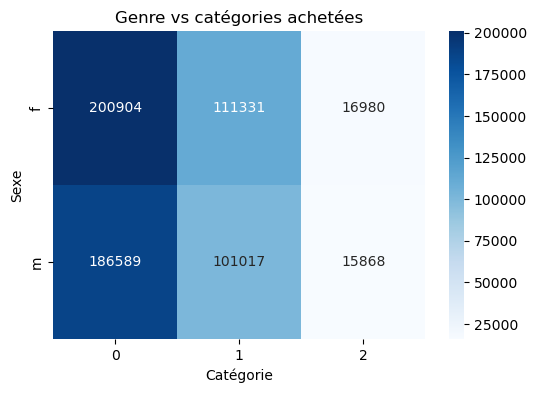

In [17]:
plt.figure(figsize=(6,4))

sns.heatmap(contingency_table, annot=True, fmt='d', cmap='Blues')

plt.title("Genre vs catégories achetées")
plt.xlabel("Catégorie")
plt.ylabel("Sexe")

plt.show()

### 2-2 : Âge et montant total des achats - test Pearson

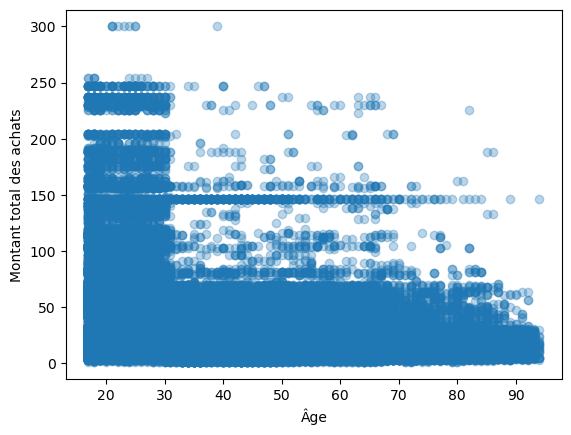

In [18]:
# L'âge et le montant total des achats sont toutes deux des variables quantitatives. 
# Comme les valeurs aberrantes ont été écartées (clients B2B), on considère que les données peuvent suivre une distribution normale.
# On vérifie cela avec un nuage de points.

plt.scatter(lapage_clean['age'], lapage_clean['price'], alpha=0.3)
plt.xlabel("Âge")
plt.ylabel("Montant total des achats")
plt.show()



Coefficient de corrélation de Pearson: -0.18674689728472177
Valeur p: 2.6237542172006073e-68


<Axes: xlabel='age', ylabel='price'>

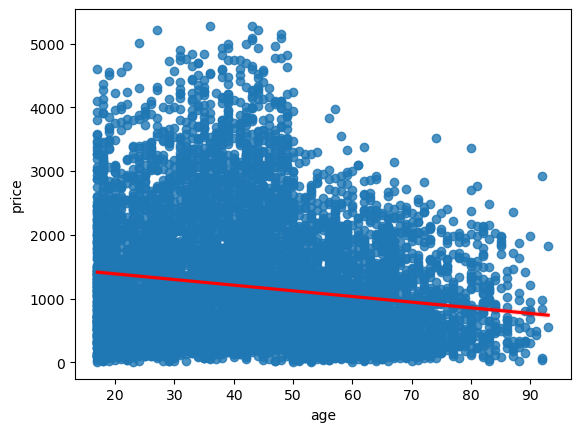

In [26]:
# Les données ont plutôt une distribution normale. On va donc utiliser le test Pearson.

from scipy.stats import pearsonr

clients_pearson = lapage_clean.groupby('client_id').agg({
    'age': 'first',
    'price': 'sum'
})

# Visualisation de la tendance

# Corrélation de Pearson
correlation, p_value = pearsonr(clients_pearson['age'], clients_pearson['price'])

print(f"Coefficient de corrélation de Pearson: {correlation}")
print(f"Valeur p: {p_value}")

sns.regplot(x=clients_pearson['age'], y=clients_pearson['price'], robust=True, line_kws=dict(color="r"))


p < 0.05 : Il existe bien une relation entre l’âge et le montant des achats.

r = -0.187 : La relation est négative.

Conclusion : plus l’âge augmente, plus le montant total des achats tend à légèrement diminuer.

### 2-3 : Âge et fréquence d’achat - test Spearman

In [21]:
# L'âge et la fréquence d'achat sont toutes deux des variables quantitatives. 

from scipy.stats import spearmanr

clients_spearman = lapage_clean.groupby('client_id').agg({
    'age': 'first',
    'session_id': 'count'
}).rename(columns={'session_id': 'frequence'})

rho, p = spearmanr(clients_spearman['age'], clients_spearman['frequence'])

print(f"Spearman rho : {rho:.3f}")
print(f"p-value : {p:.4e}")

Spearman rho : 0.130
p-value : 1.5415e-33


<Axes: xlabel='age', ylabel='frequence'>

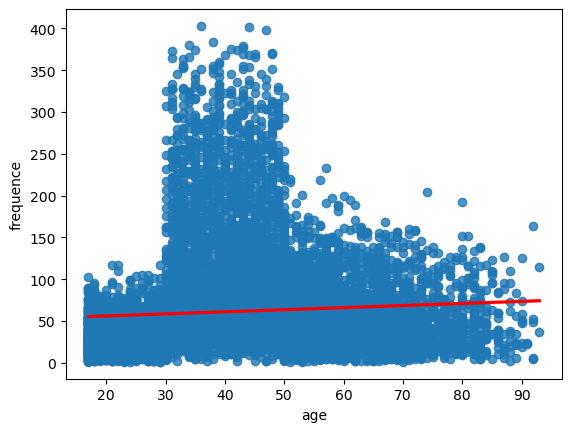

In [23]:
sns.regplot(data=clients_spearman, x="age", y="frequence", robust=True, line_kws=dict(color="r"))

p < 0.05 : il existe une relation significative entre l’âge et la fréquence d’achat.

Spearman rho = 0.130 : plus l’âge augmente, plus la fréquence d’achat tend à augmenter, mais elle augmente très légèrement.

### 3-4 : Âge et panier moyen - test Pearson

Coefficient de corrélation de Pearson: -0.5125318101431172
Valeur p: 0.0


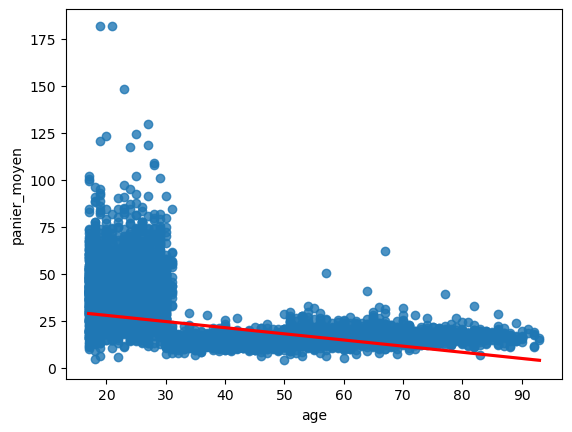

In [35]:
# L'âge et le panier moyen sont toutes deux des variables quantitatives. 
# Comme les valeurs aberrantes ont été écartées (clients B2B), on considère que les données peuvent suivre une distribution normale.

clients_panier = lapage_clean.groupby('client_id').agg({
    'age': 'first',
    'price': 'mean'
}).rename(columns={'price': 'panier_moyen'})

# Visualisation de la tendance
sns.regplot(data=clients_panier, x="age", y="panier_moyen", robust=True, line_kws=dict(color="r"))

# Calculer le coefficient de corrélation de Pearson et la valeur p
correlation, p_value = pearsonr(clients_panier['age'], clients_panier['panier_moyen'])

print(f"Coefficient de corrélation de Pearson: {correlation}")
print(f"Valeur p: {p_value}")

p < 0.05 : il existe une relation significative entre âge et panier moyen.

r = -0.513 : plus l’âge augmente, plus le panier moyen diminue.

### 2-5 : Âge et catégories achetées - test ANOVA

Statistique de test F: 40424.425295357374
Valeur p: 0.0


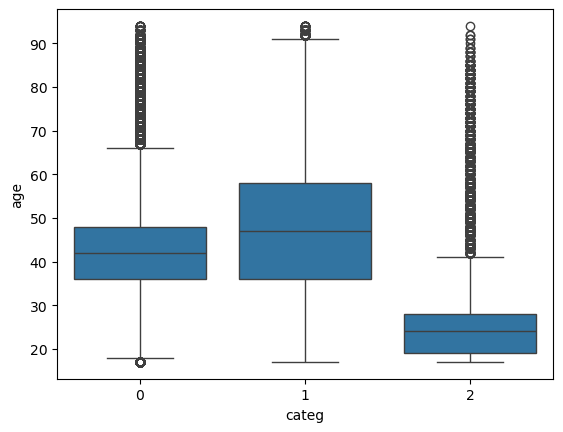

In [39]:
# L'âge est une valeur quantitative.
# La catégorie est une valeur qualitative.
# On a trois catégories, donc plusieurs groupes.
# On a donc besoin d'un test mixte, tel que le test ANOVA.

from scipy.stats import f_oneway

# On visualise nos variables d'intérêts.
sns.boxplot(x="categ", y="age", data=lapage_clean)

# Sélectionner les colonnes pertinentes pour chaque type de livres.
categ0 = lapage_clean[lapage_clean['categ'] == 0]['age'].dropna()
categ1 = lapage_clean[lapage_clean['categ'] == 1]['age'].dropna()
categ2 = lapage_clean[lapage_clean['categ'] == 2]['age'].dropna()

# Calculer le test ANOVA et la valeur p.
f_stat, p_value = f_oneway(categ0, categ1, categ2)

print(f"Statistique de test F: {f_stat}")
print(f"Valeur p: {p_value}")

p < 0.05 : les âges ne sont pas les mêmes selon les catégories.

F = 40424 : les catégories de produits sont très différenciées en âge.